<a href="https://colab.research.google.com/github/nomelegal3g/Trabalho-IBD/blob/main/Trabalho_IBD_modelo_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Título

## Sífilis em gestantes e sífilis congênita em Minas Gerais

DCC011 — Introdução a Banco de Dados — Trabalho Prático

# 2. Membros

| Nome | Matrícula |
|---|---|
| Cayo Cesar |2024001674|
| Thales Hungria | 2024001690 |
| Yago Santos | 2023095586 |

# 3. Descrição e preparação dos dados

## 3.1 Obtenção dos dados

Usamos os dados de sífilis do Sinan publicados pela Secretaria de Estado de Saúde de Minas Gerais (SES-MG) no portal de dados abertos: https://dados.mg.gov.br/dataset/sifilis

Para obter os dados, basta acessar o portal e baixar dois arquivos CSV:
- **Dados de Sífilis Gestante** (`dados_sifilis_gestante.csv`)
- **Dados Sífilis Congênita** (`dados_sifilis_congenita.csv`)

Os arquivos foram baixados em 21/10/2026.

## 3.2 Imports e funções auxiliares

Seguimos o modelo da EDA em SQL (`IBD012_eda`): as consultas são feitas direto no SQLite e as funções abaixo ajudam a executá-las (`fetch`) e a inspecionar as tabelas (`show_tables`, `shape`, `info`).

In [1]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

os.chdir("/content/drive/MyDrive/Trabalho IBD")

In [2]:
def fetch(query, conn, formatted=True):
    # execute the query and fetch all rows
    cur = conn.cursor()
    cur.execute(query)
    rs = cur.fetchall()

    # extract column names from the cursor description
    columns = [desc[0] for desc in cur.description]

    # return a dataframe with column names
    return pd.DataFrame(rs, columns=columns) if formatted else rs

def show_tables(conn):
    return [x[0] for x in fetch('SELECT tbl_name FROM sqlite_master WHERE type="table"', conn, False)]

def shape(table, conn):
    nrows = fetch(f'SELECT COUNT(*) FROM {table}', conn, False)[0][0]
    ncols = fetch(f'SELECT COUNT(*) FROM pragma_table_info("{table}")', conn, False)[0][0]

    return (nrows, ncols)

def desc(table, conn):
    cur = conn.cursor()
    cur.execute(f'PRAGMA table_info("{table}")')
    columns = [row[1] for row in cur.fetchall()]

    return columns

def info(table, conn):
    # table constraints (domain, null, default, pk)
    df1 = fetch(f'PRAGMA table_info("{table}")', conn)
    columns = desc(table, conn)

    # entries per column
    counts = ', '.join([f'COUNT(*) AS "{column}"' for column in columns])
    df2 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df2.columns = ['count']

    # non-null entries per column
    counts = ', '.join([f'COUNT("{column}") AS "{column}"' for column in columns])
    df3 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df3.columns = ['notnull count']

    # unique non-null entries per column
    counts = ', '.join([f'COUNT(DISTINCT "{column}") AS "{column}"' for column in columns])
    df4 = fetch(f'SELECT {counts} FROM "{table}"', conn).transpose()
    df4.columns = ['unique count']

    return df1.merge(df2, left_on='name', right_index=True) \
            .merge(df3, left_on='name', right_index=True) \
            .merge(df4, left_on='name', right_index=True)


## 3.3 Leitura dos arquivos

Os arquivos usam `;` como separador. Lemos todas as colunas como texto para não perder nenhuma informação.

In [3]:
gest = pd.read_csv("dados_sifilis_gestante.csv", sep=";", encoding="utf-8-sig", dtype=str)
cong = pd.read_csv("dados_sifilis_congenita.csv", sep=";", encoding="utf-8-sig", dtype=str)

print("Gestante:", gest.shape[0], "linhas e", gest.shape[1], "colunas")
print("Congênita:", cong.shape[0], "linhas e", cong.shape[1], "colunas")
print("Total:", len(gest) + len(cong), "notificações")
gest.head()

Gestante: 69511 linhas e 14 colunas
Congênita: 34904 linhas e 16 colunas
Total: 104415 notificações


,id_agravo,dt_notific,nu_ano,id_municip,id_regiona,dt_diag,dt_nasc,nu_idade_n,cs_raca,cs_escol_n,id_mn_resi,id_rg_resi,tpesquema,tratparc
0,O981,2017-08-07,2017,SÃO FRANCISCO,JANUÁRIA,2017-08-01,1981-10-21,35,Parda,4ª série completa EF,SÃO FRANCISCO,JANUÁRIA,Penicilina G benzatina 2.400.000UI,Não
1,O981,2024-10-15,2024,VIÇOSA,PONTE NOVA,2024-06-04,2002-07-26,21,Parda,Ensino fundamental completo,VIÇOSA,PONTE NOVA,Penicilina G benzatina 7.200.000UI,Não
2,O981,2024-10-17,2024,ARAPONGA,PONTE NOVA,2024-10-17,1999-03-11,25,Branca,Ensino médio completo,ARAPONGA,PONTE NOVA,Penicilina G benzatina 2.400.000UI,Sim
3,O981,2011-10-20,2011,PARAGUAÇU,AFENAS,2011-10-11,1990-07-17,21,Branca,5ª a 8ª série incompleta do EF,PARAGUAÇU,NaN,Penicilina G benzatina 2.400.000UI,Ignorado
4,O981,2019-03-07,2019,MONTES CLAROS,MONTES CLAROS,2019-03-03,1994-04-04,24,Parda,Ensino médio completo,MONTES CLAROS,MONTES CLAROS,Penicilina G benzatina 4.800.000UI,NaN


## 3.4 Entendimento dos dados

Quantidade de valores vazios em cada coluna dos arquivos originais.

In [4]:
# Quantidade de valores vazios em cada coluna
pd.DataFrame({"gestante": gest.isna().sum(), "congenita": cong.isna().sum()})

,gestante,congenita
antsifil_n,NaN,1.0
cs_escol_n,4863.0,NaN
cs_raca,420.0,510.0
cs_sexo,NaN,1435.0
dt_diag,0.0,0.0
dt_nasc,652.0,2.0
dt_notific,0.0,0.0
evolucao,NaN,0.0
id_agravo,0.0,0.0
id_mn_resi,1.0,2.0


## 3.5 Limpeza dos dados

Dois ajustes antes de normalizar:

- **Idade:** no arquivo da congênita vem com vírgula ("0,0"), então convertemos para número.
- **Regional vazia:** preenchemos com "NÃO INFORMADA".

In [5]:
for df in (gest, cong):
    df["idade"] = pd.to_numeric(df["nu_idade_n"].str.replace(",", "."), errors="coerce")
    df["id_regiona"] = df["id_regiona"].fillna("NÃO INFORMADA")
    df["id_rg_resi"] = df["id_rg_resi"].fillna("NÃO INFORMADA")

## 3.6 Normalização

Juntamos os dois arquivos em uma única tabela de notificações. Em seguida, separamos as informações que se repetem em tabelas próprias:

- **Agravo:** o código do agravo (O981 = sífilis em gestante, A509 = sífilis congênita) se repete em todas as linhas e foi para a tabela `agravo`.
- **Categoria de tratamento:** os valores de esquema terapêutico (`tpesquema` nas gestantes e `tra_esquem` na congênita) foram para a tabela `categoria_tratamento`, guardando de qual campo cada valor veio.
- **Localidade:** cada notificação tem um município/regional de **notificação** e um de **residência**. Os pares município–regional foram para a tabela `localidade`. A ligação entre notificação e localidade é **M:N** e fica na tabela `notificacao_localidade`, que indica se o local é de notificação, de residência ou os dois.
- **Notificação:** cada linha dos arquivos virou uma notificação com um identificador próprio (`id_notificacao`), porque os arquivos não têm uma chave.

Outras decisões:
- A coluna `nu_ano` foi removida, porque o ano pode ser obtido da data de notificação.
- Quando a regional está vazia, usamos o valor "NÃO INFORMADA".
- Escolaridade e tratamento do parceiro só existem para gestantes, e evolução só existe para a congênita. Nas outras linhas, essas colunas ficam vazias (`NULL`).
- Não fizemos ligação entre gestante e criança, porque os arquivos não permitem isso.

In [6]:
# Passo 1: juntar os dois arquivos em uma única tabela
gest["campo_origem"] = "tpesquema"
gest["tratamento"] = gest["tpesquema"]
cong["campo_origem"] = "tra_esquem"
cong["tratamento"] = cong["tra_esquem"]

dados = pd.concat([gest, cong], ignore_index=True)
dados["id_notificacao"] = dados.index + 1

print("Total de notificações:", len(dados))

Total de notificações: 104415


In [7]:
# Passo 2: criar as tabelas

# Tabela agravo
agravo = pd.DataFrame({
    "id_agravo": [1, 2],
    "codigo": ["O981", "A509"],
    "denominacao": ["Sífilis em gestante", "Sífilis congênita"],
})
dados["id_agravo_fk"] = dados["id_agravo"].map({"O981": 1, "A509": 2})

# Tabela categoria_tratamento
categoria = dados[["campo_origem", "tratamento"]].dropna().drop_duplicates().reset_index(drop=True)
categoria["id_categoria"] = categoria.index + 1
dados = dados.merge(categoria, on=["campo_origem", "tratamento"], how="left")
categoria = categoria.rename(columns={"tratamento": "descricao"})

# Tabela localidade (pares município-regional de notificação e de residência)
local_notif = dados[["id_notificacao", "id_municip", "id_regiona"]].copy()
local_notif.columns = ["id_notificacao", "municipio", "regional"]
local_notif["tipo"] = "notificacao"

local_resid = dados[["id_notificacao", "id_mn_resi", "id_rg_resi"]].copy()
local_resid.columns = ["id_notificacao", "municipio", "regional"]
local_resid["tipo"] = "residencia"

locais = pd.concat([local_notif, local_resid]).dropna(subset=["municipio"])

localidade = locais[["municipio", "regional"]].drop_duplicates().reset_index(drop=True)
localidade["id_localidade"] = localidade.index + 1

# Tabela notificacao_localidade (relacionamento M:N)
locais = locais.merge(localidade, on=["municipio", "regional"])
locais["eh_notificacao"] = (locais["tipo"] == "notificacao").astype(int)
locais["eh_residencia"] = (locais["tipo"] == "residencia").astype(int)
notificacao_localidade = locais.groupby(["id_notificacao", "id_localidade"], as_index=False)[["eh_notificacao", "eh_residencia"]].max()

# Tabela notificacao
notificacao = dados[["id_notificacao", "id_agravo_fk", "id_categoria", "dt_notific", "idade",
                     "cs_raca", "cs_escol_n", "tratparc", "evolucao"]]
notificacao = notificacao.rename(columns={
    "id_agravo_fk": "id_agravo",
    "dt_notific": "data_notificacao",
    "cs_raca": "raca_cor",
    "cs_escol_n": "escolaridade",
    "tratparc": "tratamento_parceiro",
})

print("agravo:", len(agravo))
print("categoria_tratamento:", len(categoria))
print("localidade:", len(localidade))
print("notificacao:", len(notificacao))
print("notificacao_localidade:", len(notificacao_localidade))

agravo: 2
categoria_tratamento: 10
localidade: 926
notificacao: 104415
notificacao_localidade: 157931


## 3.7 Criação do banco SQLite

Criamos as tabelas com chaves primárias e estrangeiras e inserimos os dados. Como o enunciado sugere, desligamos a verificação de chaves estrangeiras durante a inserção (`PRAGMA foreign_keys = 0`) e depois conferimos se está tudo certo.

In [8]:
if os.path.exists("sifilis.db"):
    os.remove("sifilis.db")
con = sqlite3.connect("sifilis.db")

con.executescript("""
CREATE TABLE agravo (
    id_agravo   INTEGER PRIMARY KEY,
    codigo      TEXT,
    denominacao TEXT
);

CREATE TABLE categoria_tratamento (
    id_categoria INTEGER PRIMARY KEY,
    campo_origem TEXT,
    descricao    TEXT
);

CREATE TABLE localidade (
    id_localidade INTEGER PRIMARY KEY,
    municipio     TEXT,
    regional      TEXT
);

CREATE TABLE notificacao (
    id_notificacao      INTEGER PRIMARY KEY,
    id_agravo           INTEGER REFERENCES agravo(id_agravo),
    id_categoria        INTEGER REFERENCES categoria_tratamento(id_categoria),
    data_notificacao    TEXT,
    idade               REAL,
    raca_cor            TEXT,
    escolaridade        TEXT,
    tratamento_parceiro TEXT,
    evolucao            TEXT
);

CREATE TABLE notificacao_localidade (
    id_notificacao INTEGER REFERENCES notificacao(id_notificacao),
    id_localidade  INTEGER REFERENCES localidade(id_localidade),
    eh_notificacao INTEGER,
    eh_residencia  INTEGER,
    PRIMARY KEY (id_notificacao, id_localidade)
);
""")

con.execute("PRAGMA foreign_keys = 0")
agravo.to_sql("agravo", con, if_exists="append", index=False)
categoria.to_sql("categoria_tratamento", con, if_exists="append", index=False)
localidade.to_sql("localidade", con, if_exists="append", index=False)
notificacao.to_sql("notificacao", con, if_exists="append", index=False)
notificacao_localidade.to_sql("notificacao_localidade", con, if_exists="append", index=False)
con.commit()
con.execute("PRAGMA foreign_keys = 1")

print("Erros de chave estrangeira:", con.execute("PRAGMA foreign_key_check").fetchall())

Erros de chave estrangeira: []


## 3.8 Inspeção das tabelas do banco

Uso das funções auxiliares para listar as tabelas e ver tipos, nulos e valores distintos da tabela `notificacao`.

In [10]:
show_tables(con)

['agravo',
 'categoria_tratamento',
 'localidade',
 'notificacao',
 'notificacao_localidade']

In [11]:
info("notificacao", con)

,cid,name,type,notnull,dflt_value,pk,count,notnull count,unique count
0,0,id_notificacao,INTEGER,0,None,1,104415,104415,104415
1,1,id_agravo,INTEGER,0,None,0,104415,104415,2
2,2,id_categoria,INTEGER,0,None,0,104415,104398,10
3,3,data_notificacao,TEXT,0,None,0,104415,104415,5754
4,4,idade,REAL,0,None,0,104415,104413,52
5,5,raca_cor,TEXT,0,None,0,104415,103485,6
6,6,escolaridade,TEXT,0,None,0,104415,64648,10
7,7,tratamento_parceiro,TEXT,0,None,0,104415,67654,3
8,8,evolucao,TEXT,0,None,0,104415,34904,6


# 4. Análise exploratória

As análises abaixo usam o banco `sifilis.db` criado na seção 3.7, com consultas SQL (JOIN, GROUP BY, subconsultas, funções de janela) e gráficos com pandas/matplotlib.

In [13]:
plt.rcParams["figure.figsize"] = (9, 4)

## 4.1 Volume de notificações por agravo

**Interpretação:** Das 104.415 notificações totais no banco de dados, a grande maioria corresponde à **Sífilis em gestante** com 69.511 casos (**66,6%**), enquanto a **Sífilis congênita** representa 34.904 casos (**33,4%**). Isso demonstra que há aproximadamente o dobro de notificações de gestantes em relação a bebês com a forma congênita da infecção.

,agravo,notificacoes,percentual
0,Sífilis congênita,34904,33.4
1,Sífilis em gestante,69511,66.6


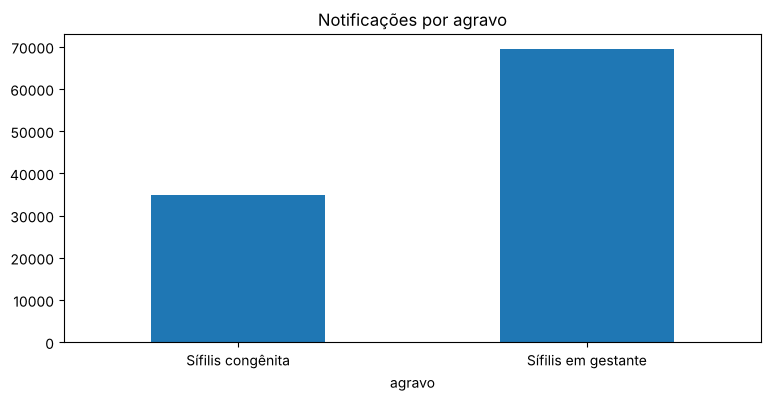

In [14]:
df = fetch("""
SELECT a.denominacao AS agravo,
       COUNT(*) AS notificacoes,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS percentual
FROM notificacao n
JOIN agravo a ON a.id_agravo = n.id_agravo
GROUP BY a.denominacao
""", con)
display(df)
df.plot.bar(x="agravo", y="notificacoes", legend=False, rot=0, title="Notificações por agravo")
plt.show()

## 4.2 Evolução anual das notificações

O ano vem da data de notificação (a coluna `nu_ano` foi removida na normalização). O último ano pode estar incompleto.

**Interpretação:** Observa-se uma tendência de crescimento consistente nas notificações de ambos os agravos ao longo dos anos. A sífilis em gestante saltou de 348 casos em 2010 para um pico de 8.023 em 2025. A sífilis congênita acompanhou essa alta, partindo de 250 casos em 2010 para 2.819 em 2025. Os dados de 2026 mostram uma aparente redução (5.790 gestantes e 2.026 congênita), mas isso se deve ao fato de o ano ainda não estar totalmente consolidado/concluído na data da coleta dos dados.

agravo,Sífilis congênita,Sífilis em gestante
ano,,
2017,2418,4042
2018,3255,5342
2019,3354,5435
2020,2520,5031
2021,2853,5581
2022,3103,6330
2023,3236,7061
2024,2735,6752
2025,2819,8023


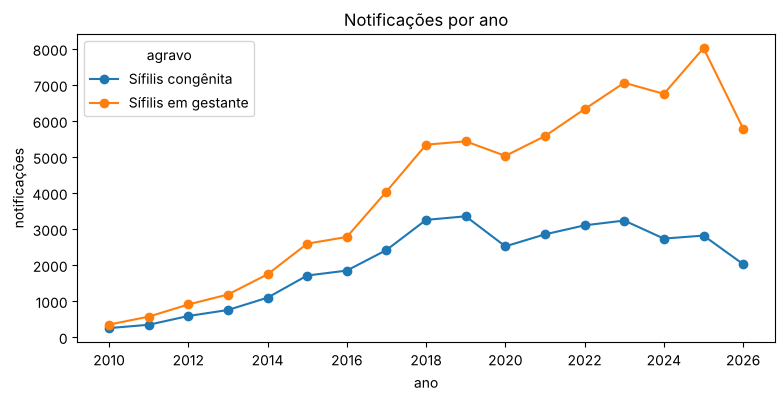

In [15]:
anual = fetch("""
SELECT CAST(strftime('%Y', n.data_notificacao) AS INTEGER) AS ano,
       a.denominacao AS agravo,
       COUNT(*) AS notificacoes
FROM notificacao n
JOIN agravo a ON a.id_agravo = n.id_agravo
WHERE n.data_notificacao IS NOT NULL
GROUP BY ano, agravo
ORDER BY ano
""", con)
pivot = anual.pivot(index="ano", columns="agravo", values="notificacoes").fillna(0)
display(pivot.tail(10))
pivot.plot(marker="o", title="Notificações por ano")
plt.ylabel("notificações")
plt.show()

## 4.3 Idade das gestantes (estatísticas descritivas e outliers)

**Interpretação:** *(a idade das gestantes mostra uma tendência de acumulação em torno dos 20 anos com uma calda alongada em direção aos 50 anos, em linha com a idade fértil das mulheres, cabe destaque no valor mínimo sendo uma idade de 10 anos e máximo 57)*

,gestantes
count,69511.0
mean,24.4
std,6.1
min,10.0
25%,20.0
50%,23.0
75%,28.0
max,57.0


Outliers pelo critério do IQR: 865 (1.24%)
Menores de 10 anos: 0 | Maiores de 55 anos: 1


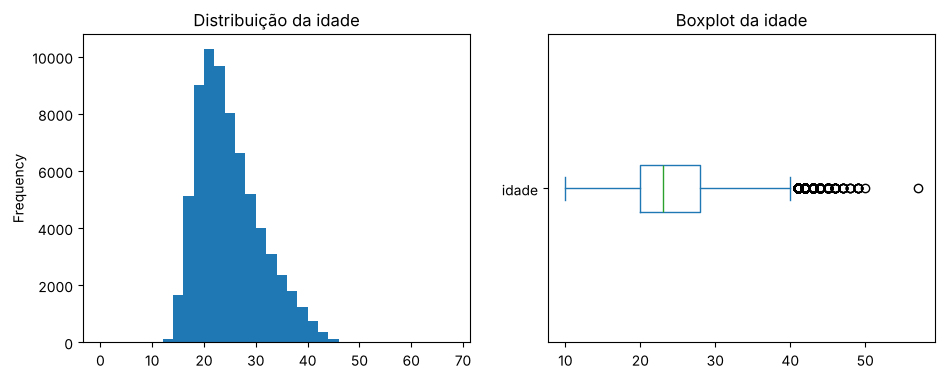

In [16]:
idade_g = fetch("SELECT idade FROM notificacao WHERE id_agravo = 1 AND idade IS NOT NULL", con)["idade"]
display(idade_g.describe().round(1).to_frame("gestantes"))

q1, q3 = idade_g.quantile([0.25, 0.75])
iqr = q3 - q1
fora = idade_g[(idade_g < q1 - 1.5 * iqr) | (idade_g > q3 + 1.5 * iqr)]
print(f"Outliers pelo critério do IQR: {len(fora)} ({100*len(fora)/len(idade_g):.2f}%)")
print("Menores de 10 anos:", (idade_g < 10).sum(), "| Maiores de 55 anos:", (idade_g > 55).sum())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
idade_g.plot.hist(bins=range(0, 70, 2), ax=ax[0], title="Distribuição da idade")
idade_g.plot.box(ax=ax[1], vert=False, title="Boxplot da idade")
plt.show()

## 4.4 Idade nas notificações de sífilis congênita

Na congênita a idade é a da **criança**, então ela não deve ser comparada com a das gestantes.

**Interpretação:** Como esperado para a sífilis congênita (transmitida da mãe para o bebê na gestação ou parto), a esmagadora maioria das notificações ocorre na idade **0.0** (recém-nascidos), somando 34.516 casos do total. Há um número residual muito baixo de diagnósticos tardios feitos em crianças de 1 a 12 anos, indicando que a detecção é massivamente realizada logo após o nascimento.

In [17]:
fetch("""
SELECT idade, COUNT(*) AS notificacoes
FROM notificacao
WHERE id_agravo = 2
GROUP BY idade
ORDER BY notificacoes DESC
LIMIT 10
""", con)

,idade,notificacoes
0,0.0,34516
1,1.0,249
2,2.0,64
3,3.0,26
4,4.0,10
5,5.0,9
6,6.0,7
7,10.0,6
8,12.0,5
9,9.0,4


## 4.5 Raça/cor por agravo (percentual dentro de cada agravo)

**Interpretação:** A distribuição de raça/cor é muito semelhante em ambos os agravos. A população **Parda** é a mais afetada, representando **53,8%** dos casos de sífilis congênita e **53,1%** de sífilis em gestante. A população **Branca** aparece em segundo lugar (~22% em ambos), seguida por um volume expressivo de dados **Ignorados** (16,1% na congênita e 6,5% na gestante), o que aponta uma oportunidade de melhoria no preenchimento das fichas.

,agravo,raca_cor,notificacoes,percentual
0,Sífilis congênita,Parda,18765,53.8
1,Sífilis congênita,Branca,7805,22.4
2,Sífilis congênita,Ignorado,5617,16.1
3,Sífilis congênita,Preta,2052,5.9
4,Sífilis congênita,Em branco,510,1.5
5,Sífilis congênita,Amarela,125,0.4
6,Sífilis congênita,Indígena,30,0.1
7,Sífilis em gestante,Parda,37796,54.4
8,Sífilis em gestante,Branca,15504,22.3
9,Sífilis em gestante,Preta,10592,15.2


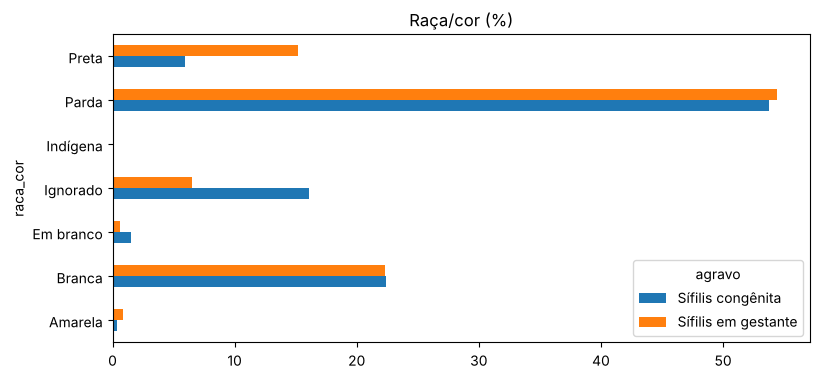

In [18]:
raca = fetch("""
SELECT a.denominacao AS agravo,
       COALESCE(n.raca_cor, 'Em branco') AS raca_cor,
       COUNT(*) AS notificacoes,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY a.denominacao), 1) AS percentual
FROM notificacao n
JOIN agravo a ON a.id_agravo = n.id_agravo
GROUP BY a.denominacao, COALESCE(n.raca_cor, 'Em branco')
ORDER BY a.denominacao, notificacoes DESC
""", con)
display(raca)
raca.pivot(index="raca_cor", columns="agravo", values="percentual").plot.barh(title="Raça/cor (%)")
plt.show()

## 4.6 Escolaridade das gestantes

**Interpretação:** O dado de escolaridade possui uma limitação séria de preenchimento: a categoria mais frequente é **Ignorado**, com **30,9%** (21.487 gestantes). Entre as notificações com escolaridade preenchida, destaca-se o Ensino Médio Completo (21,4%), seguido pelo Ensino Médio Incompleto (13,1%) e Fundamental Incompleto (11,8%). Isso sugere a necessidade de maior atenção das equipes de saúde ao registrar essa variável socioeconômica importante.

,escolaridade,gestantes,percentual
0,Ignorado,21487,30.9
1,Ensino médio completo,14877,21.4
2,Ensino médio incompleto,9118,13.1
3,5ª a 8ª série incompleta do EF,8215,11.8
4,Ensino fundamental completo,6756,9.7
5,Em branco,4863,7.0
6,4ª série completa EF,1351,1.9
7,1ª a 4ª série incompleta do EF,1320,1.9
8,Educação superior completa,788,1.1
9,Educação superior incompleta,734,1.1


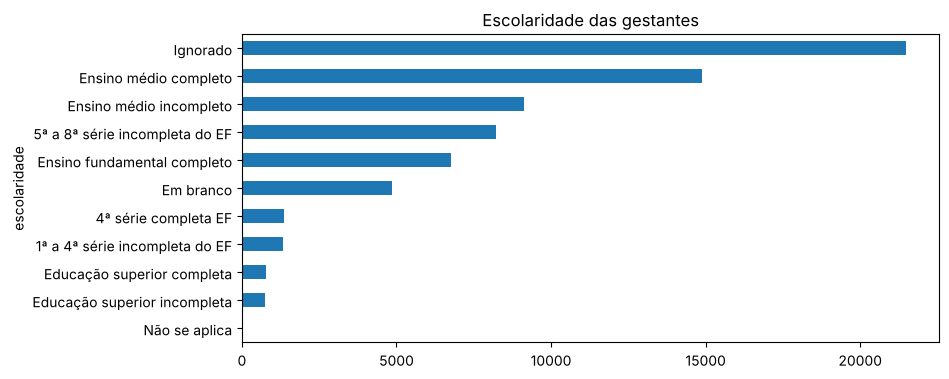

In [19]:
esc = fetch("""
SELECT COALESCE(escolaridade, 'Em branco') AS escolaridade,
       COUNT(*) AS gestantes,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS percentual
FROM notificacao
WHERE id_agravo = 1
GROUP BY COALESCE(escolaridade, 'Em branco')
ORDER BY gestantes DESC
""", con)
display(esc)
esc.set_index("escolaridade")["gestantes"].sort_values().plot.barh(title="Escolaridade das gestantes")
plt.show()

## 4.7 Tratamento do parceiro (gestantes)

**Interpretação:** Em **46,1%** dos casos notificados de sífilis em gestantes, o parceiro **não** realizou o tratamento. Apenas **33,6%** dos parceiros foram tratados. O não tratamento do parceiro é um dos fatores mais críticos para a reinfecção da gestante e consequente transmissão vertical da doença para o bebê, justificando o alto volume de sífilis congênita.

In [20]:
fetch("""
SELECT COALESCE(tratamento_parceiro, 'Em branco') AS tratamento_parceiro,
       COUNT(*) AS gestantes,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS percentual
FROM notificacao
WHERE id_agravo = 1
GROUP BY COALESCE(tratamento_parceiro, 'Em branco')
ORDER BY gestantes DESC
""", con)

,tratamento_parceiro,gestantes,percentual
0,Não,32075,46.1
1,Sim,23377,33.6
2,Ignorado,12202,17.6
3,Em branco,1857,2.7


## 4.8 Esquema terapêutico por agravo

**Interpretação:** Para as gestantes, o principal tratamento utilizado é a Penicilina G benzatina 7.200.000UI (**57,8%** das notificações). Já no caso da sífilis congênita, a classificação do tratamento materno revela um cenário preocupante: em **44,4%** dos casos (15.508 notificações) o tratamento da mãe foi considerado **Inadequado**, e em **20,1%** (7.016 casos) **não foi realizado**, totalizando quase 65% de falhas ou ausência de intervenção terapêutica materna eficaz antes do parto.

In [21]:
trat = fetch("""
SELECT a.denominacao AS agravo,
       c.descricao AS esquema,
       COUNT(*) AS notificacoes,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY a.denominacao), 1) AS percentual
FROM notificacao n
JOIN agravo a ON a.id_agravo = n.id_agravo
JOIN categoria_tratamento c ON c.id_categoria = n.id_categoria
GROUP BY a.denominacao, c.descricao
ORDER BY a.denominacao, notificacoes DESC
""", con)
display(trat)

,agravo,esquema,notificacoes,percentual
0,Sífilis congênita,Inadequado,15508,44.4
1,Sífilis congênita,Adequado,9413,27.0
2,Sífilis congênita,Não realizado,7016,20.1
3,Sífilis congênita,Ignorado,2966,8.5
4,Sífilis em gestante,Penicilina G benzatina 7.200.000UI,40191,57.8
5,Sífilis em gestante,Penicilina G benzatina 2.400.000UI,16181,23.3
6,Sífilis em gestante,Não realizado,5204,7.5
7,Sífilis em gestante,Penicilina G benzatina 4.800.000UI,2945,4.2
8,Sífilis em gestante,Ignorado,2901,4.2
9,Sífilis em gestante,Outro esquema,2073,3.0


## 4.9 Municípios que mais notificam

Usa a tabela de ligação `notificacao_localidade`, filtrando os locais de notificação (`eh_notificacao = 1`).

**Interpretação:** Como maior polo urbano do estado, **Belo Horizonte** lidera isoladamente as notificações com um total de 27.592 casos (16.352 gestantes e 11.240 congênitas). Juiz de Fora (4.836) e Governador Valadares (4.183) completam as três primeiras posições. É notável que Ipatinga apresenta um volume proporcional de sífilis congênita atipicamente elevado comparado ao seu número de gestantes notificadas.

,municipio,total,gestantes,congenita
0,BELO HORIZONTE,27592,16352,11240
1,JUIZ DE FORA,4836,3007,1829
2,GOVERNADOR VALADARES,4183,2599,1584
3,BETIM,3749,2369,1380
4,CONTAGEM,3568,2169,1399
5,UBERABA,3494,2305,1189
6,UBERLÂNDIA,3338,2165,1173
7,IPATINGA,3117,1436,1681
8,MONTES CLAROS,2722,1757,965
9,RIBEIRÃO DAS NEVES,1762,1379,383


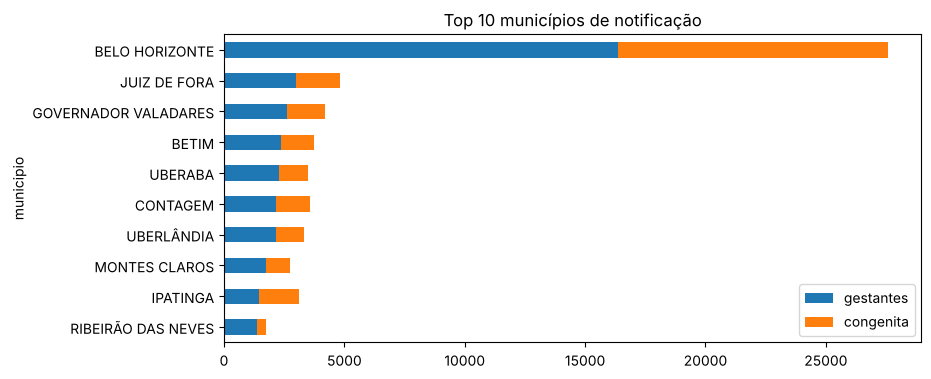

In [22]:
top_mun = fetch("""
SELECT l.municipio,
       COUNT(*) AS total,
       SUM(n.id_agravo = 1) AS gestantes,
       SUM(n.id_agravo = 2) AS congenita
FROM notificacao_localidade nl
JOIN localidade l ON l.id_localidade = nl.id_localidade
JOIN notificacao n ON n.id_notificacao = nl.id_notificacao
WHERE nl.eh_notificacao = 1
GROUP BY l.municipio
ORDER BY total DESC
LIMIT 10
""", con)
display(top_mun)
top_mun.set_index("municipio")[["gestantes", "congenita"]].sort_values("gestantes").plot.barh(stacked=True, title="Top 10 municípios de notificação")
plt.show()

## 4.10 Regionais de residência: casos de sífilis congênita para cada 100 de gestante

Razão entre as duas notificações por regional de residência (`eh_residencia = 1`), só para regionais com pelo menos 100 notificações de gestante. Não é uma taxa de transmissão, porque os arquivos não ligam a gestante à criança.

**Interpretação:** A regional de **Pirapora** apresenta a maior proporção do estado, registrando **88,3** casos de sífilis congênita para cada 100 gestantes notificadas. Teófilo Otoni (75,4) e Coronel Fabriciano (71,1) também registram índices muito elevados. Esses números sugerem possíveis fragilidades locais na cobertura ou eficácia do pré-natal para evitar a evolução da infecção materna para a forma congênita no feto.

,regional,gestantes,congenita,congenita_por_100_gestantes
0,PIRAPORA,495,437,88.3
1,TEÓFILO OTONI,1552,1170,75.4
2,CORONEL FABRICIANO,2821,2007,71.1
3,PEDRA AZUL,540,332,61.5
4,JUIZ DE FORA,3289,1831,55.7
5,SÃO JOÃO DEL REI,444,241,54.3
6,GOVERNADOR VALADARES,3331,1799,54.0
7,PATOS DE MINAS,1066,563,52.8
8,MONTES CLAROS,3002,1538,51.2
9,LEOPOLDINA,657,324,49.3


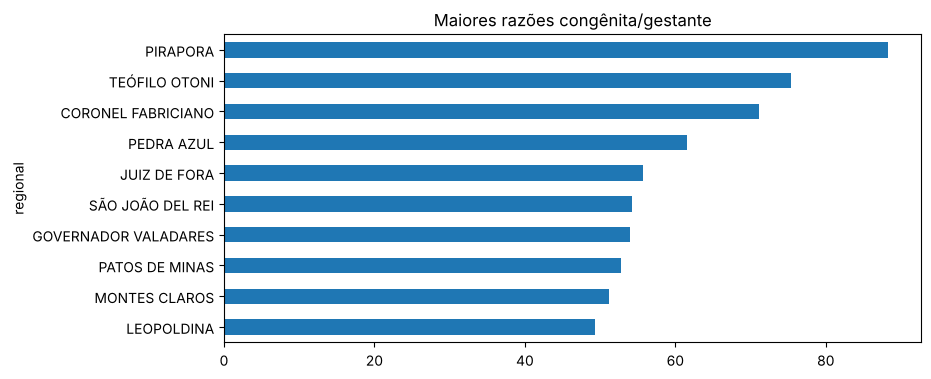

In [23]:
razao = fetch("""
SELECT l.regional,
       SUM(n.id_agravo = 1) AS gestantes,
       SUM(n.id_agravo = 2) AS congenita,
       ROUND(100.0 * SUM(n.id_agravo = 2) / SUM(n.id_agravo = 1), 1) AS congenita_por_100_gestantes
FROM notificacao_localidade nl
JOIN localidade l ON l.id_localidade = nl.id_localidade
JOIN notificacao n ON n.id_notificacao = nl.id_notificacao
WHERE nl.eh_residencia = 1 AND l.regional <> 'NÃO INFORMADA'
GROUP BY l.regional
HAVING SUM(n.id_agravo = 1) >= 100
ORDER BY congenita_por_100_gestantes DESC
""", con)
display(razao.head(10))
razao.head(10).set_index("regional")["congenita_por_100_gestantes"].sort_values().plot.barh(title="Maiores razões congênita/gestante")
plt.show()

## 4.11 Notificações feitas fora do município de residência (subconsulta)

Uma notificação é considerada "fora do município" quando não existe localidade que seja ao mesmo tempo de notificação e de residência.

**Interpretação:** Um percentual muito elevado de casos é notificado fora do município onde a pessoa reside: **61,1%** para sífilis congênita e **46,4%** para sífilis em gestante. Isso evidencia o fluxo de deslocamento de pacientes para a realização de partos ou tratamentos especializados em municípios polo que possuem infraestrutura hospitalar de referência.

In [24]:
fetch("""
SELECT a.denominacao AS agravo,
       COUNT(*) AS notificacoes,
       SUM(CASE WHEN NOT EXISTS (
               SELECT 1 FROM notificacao_localidade nl
               WHERE nl.id_notificacao = n.id_notificacao
                 AND nl.eh_notificacao = 1 AND nl.eh_residencia = 1
           ) THEN 1 ELSE 0 END) AS fora_do_municipio
FROM notificacao n
JOIN agravo a ON a.id_agravo = n.id_agravo
GROUP BY a.denominacao
""", con).assign(percentual=lambda d: (100 * d.fora_do_municipio / d.notificacoes).round(1))

,agravo,notificacoes,fora_do_municipio,percentual
0,Sífilis congênita,34904,21343,61.1
1,Sífilis em gestante,69511,32248,46.4


## 4.12 Evolução dos casos de sífilis congênita

**Interpretação:** Felizmente, a maioria esmagadora dos recém-nascidos notificados com sífilis congênita evolui para a condição de **Vivo** (**89,8%**). Contudo, há registros preocupantes de desfechos graves como natimortos (2,3% / 805 casos), abortos (1,7% / 604 casos) e óbitos diretamente atribuídos à sífilis congênita (1,3% / 450 casos), reforçando a gravidade da doença quando não prevenida.

In [25]:
evo = fetch("""
SELECT COALESCE(evolucao, 'Em branco') AS evolucao,
       COUNT(*) AS casos,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS percentual
FROM notificacao
WHERE id_agravo = 2
GROUP BY COALESCE(evolucao, 'Em branco')
ORDER BY casos DESC
""", con)
display(evo)

,evolucao,casos,percentual
0,Vivo,31329,89.8
1,Ignorado,1455,4.2
2,Natimorto,805,2.3
3,Aborto,604,1.7
4,Óbito por sífilis congênita,450,1.3
5,Óbito por outras causas,261,0.7


## 4.13 Qualidade dos dados: campos em branco por agravo

**Interpretação:** A análise de completude dos dados confirma que algumas variáveis essenciais possuem excelente preenchimento (idade e tratamento possuem 0% de nulos). No entanto, há limitações importantes dependendo do agravo: a escolaridade está ausente em 7% dos casos das gestantes e 100% na congênita (o que é esperado por se tratar de bebês), e o tratamento do parceiro está ausente em 2,7% das fichas de gestantes.

In [26]:
fetch("""
SELECT a.denominacao AS agravo,
       COUNT(*) AS total,
       ROUND(100.0 * SUM(n.idade IS NULL) / COUNT(*), 1)          AS pct_sem_idade,
       ROUND(100.0 * SUM(n.raca_cor IS NULL) / COUNT(*), 1)       AS pct_sem_raca,
       ROUND(100.0 * SUM(n.id_categoria IS NULL) / COUNT(*), 1)   AS pct_sem_tratamento,
       ROUND(100.0 * SUM(n.escolaridade IS NULL) / COUNT(*), 1)   AS pct_sem_escolaridade,
       ROUND(100.0 * SUM(n.tratamento_parceiro IS NULL) / COUNT(*), 1) AS pct_sem_trat_parceiro
FROM notificacao n
JOIN agravo a ON a.id_agravo = n.id_agravo
GROUP BY a.denominacao
""", con)

,agravo,total,pct_sem_idade,pct_sem_raca,pct_sem_tratamento,pct_sem_escolaridade,pct_sem_trat_parceiro
0,Sífilis congênita,34904,0.0,1.5,0.0,100.0,100.0
1,Sífilis em gestante,69511,0.0,0.6,0.0,7.0,2.7


## 4.14 Conclusões

*(Resuma aqui, em poucos tópicos, os principais achados das análises acima, as limitações dos dados e possíveis próximos passos.)*